<a href="https://colab.research.google.com/github/myroslav284/laptop-price-prediciton/blob/main/laptop_price.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv('./laptop_price.csv', encoding='ISO-8859-1')

In [ ]:
df.head()

,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros
0,1,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,1339.69
1,2,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,898.94
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,575.00
3,4,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,2537.45
4,5,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,1803.60


In [ ]:
print(f'duplicated values: {df.duplicated().sum().item()}')

duplicated values: 0


In [ ]:
df.isna().sum()

,0
laptop_ID,0
Company,0
Product,0
TypeName,0
Inches,0
ScreenResolution,0
Cpu,0
Ram,0
Memory,0
Gpu,0


In [ ]:
df.columns

Index(['laptop_ID', 'Company', 'Product', 'TypeName', 'Inches',
       'ScreenResolution', 'Cpu', 'Ram', 'Memory', 'Gpu', 'OpSys', 'Weight',
       'Price_euros'],
      dtype='object')

First task transform column CPU in CPU_Company', 'CPU_Type', 'CPU_Frequency (GHz)
Gpu - GPU_Company', 'GPU_Type'


In [ ]:
df['Gpu'].head()

,Gpu
0,Intel Iris Plus Graphics 640
1,Intel HD Graphics 6000
2,Intel HD Graphics 620
3,AMD Radeon Pro 455
4,Intel Iris Plus Graphics 650


In [ ]:
def extract_cpu_data(cpu_string):
  cpu_array = cpu_string.split()
  cpu_company = cpu_array[0]
  cpu_type = cpu_array[1:-1]
  cpu_type = ' '.join(cpu_type)
  cpu_frequency = cpu_array[-1].replace('GHz', '')
  try :
    cpu_frequency = float(cpu_frequency)
  except ValueError:
    frequency = None
  return pd.Series([cpu_company, cpu_type, cpu_frequency])
def extract_gpu_data(gpu_string):
  gpu_array = gpu_string.split()
  gpu_company = gpu_array[0]
  gpu_type = gpu_array[1:-1]
  return pd.Series([gpu_company, gpu_type])
df[['CPU_Company', 'CPU_Type', 'CPU_Frequency (GHz)']] = df['Cpu'].apply(extract_cpu_data)
df[['GPU_Company', 'GPU_Type']] = df['Gpu'].apply(extract_gpu_data)

In [ ]:
df['Ram'] = df['Ram'].str.replace('GB', '').astype(int)
df['Weight'] = df['Weight'].str.replace('kg', '').astype(float)

df.drop(columns=['laptop_ID', 'Cpu', 'Gpu'], inplace=True)

new_order = ['Company', 'Product', 'TypeName', 'Inches',
       'ScreenResolution', 'CPU_Company', 'CPU_Type', 'CPU_Frequency (GHz)', 'Ram', 'Memory',
       'GPU_Company', 'GPU_Type', 'OpSys', 'Weight',
       'Price_euros']
df = df[new_order]

df.rename(columns={'Ram': 'RAM (GB)' , 'Weight': 'Weight (kg)' , 'Price_euros':'Price (Euro)'}, inplace=True)

In [ ]:
df.head()

,Company,Product,TypeName,Inches,ScreenResolution,CPU_Company,CPU_Type,CPU_Frequency (GHz),RAM (GB),Memory,GPU_Company,GPU_Type,OpSys,Weight (kg),Price (Euro)
0,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel,Core i5,2.3,8,128GB SSD,Intel,"[Iris, Plus, Graphics]",macOS,1.37,1339.69
1,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel,Core i5,1.8,8,128GB Flash Storage,Intel,"[HD, Graphics]",macOS,1.34,898.94
2,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel,Core i5 7200U,2.5,8,256GB SSD,Intel,"[HD, Graphics]",No OS,1.86,575.00
3,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel,Core i7,2.7,16,512GB SSD,AMD,"[Radeon, Pro]",macOS,1.83,2537.45
4,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel,Core i5,3.1,8,256GB SSD,Intel,"[Iris, Plus, Graphics]",macOS,1.37,1803.60


In [ ]:
df.columns

Index(['Company', 'Product', 'TypeName', 'Inches', 'ScreenResolution',
       'CPU_Company', 'CPU_Type', 'CPU_Frequency (GHz)', 'RAM (GB)', 'Memory',
       'GPU_Company', 'GPU_Type', 'OpSys', 'Weight (kg)', 'Price (Euro)'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Company              1303 non-null   object 
 1   Product              1303 non-null   object 
 2   TypeName             1303 non-null   object 
 3   Inches               1303 non-null   float64
 4   ScreenResolution     1303 non-null   object 
 5   CPU_Company          1303 non-null   object 
 6   CPU_Type             1303 non-null   object 
 7   CPU_Frequency (GHz)  1303 non-null   float64
 8   RAM (GB)             1303 non-null   int64  
 9   Memory               1303 non-null   object 
 10  GPU_Company          1303 non-null   object 
 11  GPU_Type             1303 non-null   object 
 12  OpSys                1303 non-null   object 
 13  Weight (kg)          1303 non-null   float64
 14  Price (Euro)         1303 non-null   float64
dtypes: float64(4), int64(1), object(10)
me

Numberical data


In [ ]:
numerical_col = [feature for feature in df.columns if df[feature].dtype != "object"]
category_col = [feature for feature in df.columns if df[feature].dtype == "object"]
numerical_col

['Inches', 'CPU_Frequency (GHz)', 'RAM (GB)', 'Weight (kg)', 'Price (Euro)']

In [ ]:
# Convert all list elements to tuples (tuples are hashable)
df = df.applymap(lambda x: tuple(x) if isinstance(x, list) else x)

# Now check for duplicates
print(f'duplicated values: {df.duplicated().sum()}')


duplicated values: 28


<ipython-input-14-d4e5685bda99>:2: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df = df.applymap(lambda x: tuple(x) if isinstance(x, list) else x)


In [ ]:
df.describe(include='all')

,Company,Product,TypeName,Inches,ScreenResolution,CPU_Company,CPU_Type,CPU_Frequency (GHz),RAM (GB),Memory,GPU_Company,GPU_Type,OpSys,Weight (kg),Price (Euro)
count,1303,1303,1303,1303.000000,1303,1303,1303,1303.000000,1303.000000,1303,1303,1303,1303,1303.000000,1303.000000
unique,19,618,6,NaN,40,3,93,NaN,NaN,39,4,26,9,NaN,NaN
top,Dell,XPS 13,Notebook,NaN,Full HD 1920x1080,Intel,Core i5 7200U,NaN,NaN,256GB SSD,Intel,"(HD, Graphics)",Windows 10,NaN,NaN
freq,297,30,727,NaN,507,1240,193,NaN,NaN,412,722,610,1072,NaN,NaN
mean,NaN,NaN,NaN,15.017191,NaN,NaN,NaN,2.298772,8.382195,NaN,NaN,NaN,NaN,2.038734,1123.686992
std,NaN,NaN,NaN,1.426304,NaN,NaN,NaN,0.506340,5.084665,NaN,NaN,NaN,NaN,0.665475,699.009043
min,NaN,NaN,NaN,10.100000,NaN,NaN,NaN,0.900000,2.000000,NaN,NaN,NaN,NaN,0.690000,174.000000
25%,NaN,NaN,NaN,14.000000,NaN,NaN,NaN,2.000000,4.000000,NaN,NaN,NaN,NaN,1.500000,599.000000
50%,NaN,NaN,NaN,15.600000,NaN,NaN,NaN,2.500000,8.000000,NaN,NaN,NaN,NaN,2.040000,977.000000
75%,NaN,NaN,NaN,15.600000,NaN,NaN,NaN,2.700000,8.000000,NaN,NaN,NaN,NaN,2.300000,1487.880000


In [ ]:
duplicates = df[df.duplicated(keep=False)]
duplicates

,Company,Product,TypeName,Inches,ScreenResolution,CPU_Company,CPU_Type,CPU_Frequency (GHz),RAM (GB),Memory,GPU_Company,GPU_Type,OpSys,Weight (kg),Price (Euro)
1261,Asus,ZenBook UX305CA-UBM1,Ultrabook,13.3,IPS Panel Full HD 1920x1080,Intel,Core M 6Y30,0.9,8,512GB SSD,Intel,"(HD, Graphics)",Windows 10,1.20,729.00
1262,Dell,Inspiron 3567,Notebook,15.6,1366x768,Intel,Core i3 7100U,2.4,6,1TB HDD,Intel,"(HD, Graphics)",Windows 10,2.30,459.00
1263,Acer,Aspire ES1-531,Notebook,15.6,1366x768,Intel,Celeron Dual Core N3060,1.6,4,500GB HDD,Intel,"(HD, Graphics)",Linux,2.40,289.00
1264,Dell,Inspiron 3552,Notebook,15.6,1366x768,Intel,Celeron Dual Core N3050,1.6,2,500GB HDD,Intel,"(HD,)",Windows 10,2.20,379.00
1265,Lenovo,IdeaPad Y700-15ISK,Notebook,15.6,IPS Panel Full HD 1920x1080,Intel,Core i7 6700HQ,2.6,8,1TB HDD,Nvidia,"(GeForce, GTX)",Windows 10,2.60,899.00
1266,HP,Pavilion 15-AW003nv,Notebook,15.6,Full HD 1920x1080,AMD,A9-Series 9410,2.9,6,1.0TB Hybrid,AMD,"(Radeon, R7)",Windows 10,2.04,549.99
1267,Dell,Inspiron 3567,Notebook,15.6,1366x768,Intel,Core i7 7500U,2.7,8,1TB HDD,AMD,"(Radeon, R5)",Linux,2.30,805.99
1268,HP,Stream 11-Y000na,Netbook,11.6,1366x768,Intel,Celeron Dual Core N3060,1.6,2,32GB Flash Storage,Intel,"(HD, Graphics)",Windows 10,1.17,209.00
1269,Asus,X556UJ-XO044T (i7-6500U/4GB/500GB/GeForce,Notebook,15.6,1366x768,Intel,Core i7 6500U,2.5,4,500GB HDD,Nvidia,"(GeForce,)",Windows 10,2.20,720.32
1270,Lenovo,Yoga 500-14ISK,2 in 1 Convertible,14.0,IPS Panel Full HD / Touchscreen 1920x1080,Intel,Core i7 6500U,2.5,4,128GB SSD,Intel,"(HD, Graphics)",Windows 10,1.80,638.00


In [ ]:
df = df.drop_duplicates()
df

,Company,Product,TypeName,Inches,ScreenResolution,CPU_Company,CPU_Type,CPU_Frequency (GHz),RAM (GB),Memory,GPU_Company,GPU_Type,OpSys,Weight (kg),Price (Euro)
0,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel,Core i5,2.3,8,128GB SSD,Intel,"(Iris, Plus, Graphics)",macOS,1.37,1339.69
1,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel,Core i5,1.8,8,128GB Flash Storage,Intel,"(HD, Graphics)",macOS,1.34,898.94
2,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel,Core i5 7200U,2.5,8,256GB SSD,Intel,"(HD, Graphics)",No OS,1.86,575.00
3,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel,Core i7,2.7,16,512GB SSD,AMD,"(Radeon, Pro)",macOS,1.83,2537.45
4,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel,Core i5,3.1,8,256GB SSD,Intel,"(Iris, Plus, Graphics)",macOS,1.37,1803.60
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1270,Lenovo,Yoga 500-14ISK,2 in 1 Convertible,14.0,IPS Panel Full HD / Touchscreen 1920x1080,Intel,Core i7 6500U,2.5,4,128GB SSD,Intel,"(HD, Graphics)",Windows 10,1.80,638.00
1271,Lenovo,Yoga 900-13ISK,2 in 1 Convertible,13.3,IPS Panel Quad HD+ / Touchscreen 3200x1800,Intel,Core i7 6500U,2.5,16,512GB SSD,Intel,"(HD, Graphics)",Windows 10,1.30,1499.00
1272,Lenovo,IdeaPad 100S-14IBR,Notebook,14.0,1366x768,Intel,Celeron Dual Core N3050,1.6,2,64GB Flash Storage,Intel,"(HD,)",Windows 10,1.50,229.00
1273,HP,15-AC110nv (i7-6500U/6GB/1TB/Radeon,Notebook,15.6,1366x768,Intel,Core i7 6500U,2.5,6,1TB HDD,AMD,"(Radeon, R5)",Windows 10,2.19,764.00


In [ ]:
df.duplicated().sum()

0

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

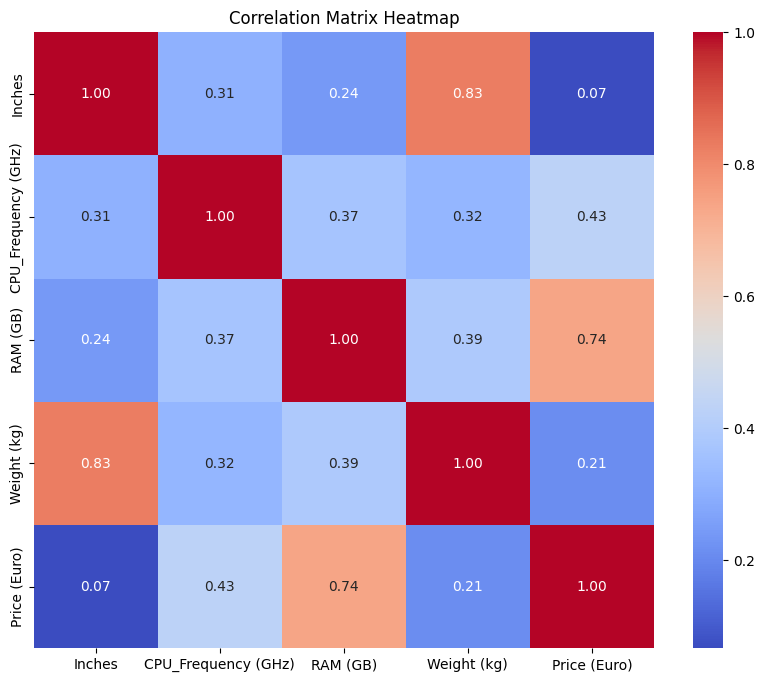

In [ ]:
# Compute correlation matrix
correlation_matrix = df[numerical_col].corr()

# Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix Heatmap')
plt.show()

Company


,count
Company,
Dell,291
Lenovo,289
HP,268
Asus,152
Acer,101
MSI,54
Toshiba,48
Apple,21
Samsung,9


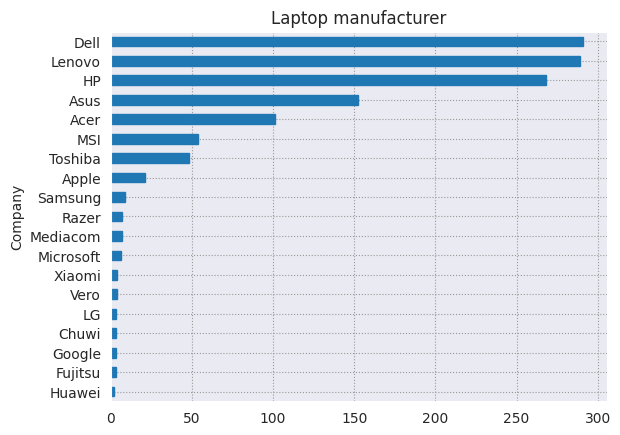

In [ ]:
company = df['Company'].value_counts()

sns.set_style('darkgrid', {"grid.color": "0.6", "grid.linestyle": ":"})
company = company.sort_values(ascending=True)
company.plot(kind='barh', edgecolor='#1F77B4', title='Laptop manufacturer')
pd.DataFrame(company.sort_values(ascending=False))

,count
TypeName,
Notebook,707
Gaming,205
Ultrabook,194
2 in 1 Convertible,117
Workstation,29
Netbook,23


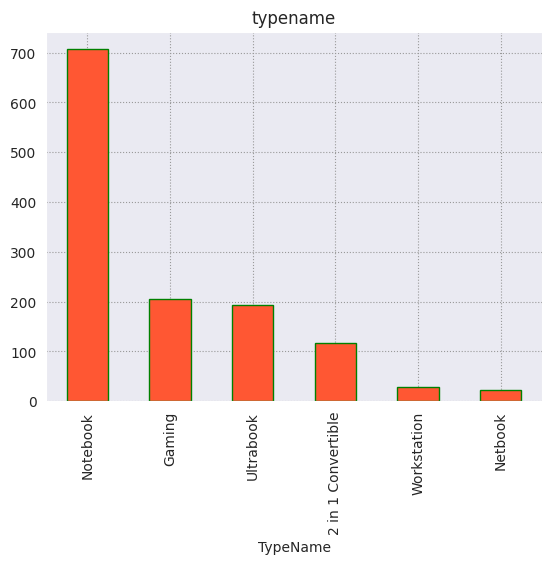

In [ ]:
typename = df['TypeName'].value_counts()
sns.set_style('darkgrid', {"grid.color": "0.6", "grid.linestyle": ":"})
typename.plot(kind='bar', edgecolor='green', color='#FF5733', title='typename')
pd.DataFrame(typename)

,count
Inches,
15.6,647
14.0,193
17.3,164
13.3,160
12.5,39
11.6,31
12.0,6
13.5,6
13.9,6


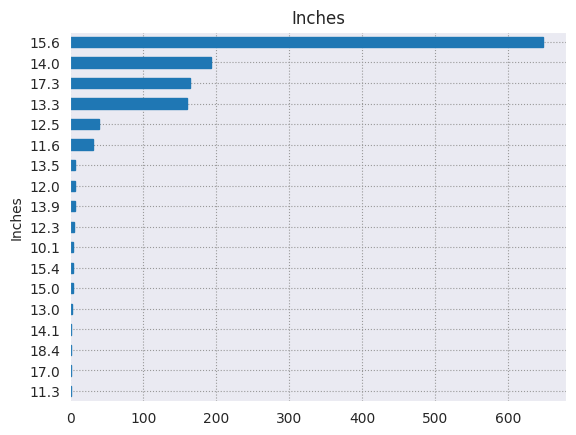

In [ ]:
Inches = df['Inches'].value_counts()
Inches = Inches.sort_values(ascending=True)
sns.set_style('darkgrid', {"grid.color": "0.6", "grid.linestyle": ":"})
Inches.plot(kind='barh', edgecolor='#1F77B4', title='Inches')
pd.DataFrame(Inches.sort_values(ascending=False))

,count
ScreenResolution,
Full HD 1920x1080,505
1366x768,263
IPS Panel Full HD 1920x1080,226
IPS Panel Full HD / Touchscreen 1920x1080,51
Full HD / Touchscreen 1920x1080,47
1600x900,23
Touchscreen 1366x768,16
Quad HD+ / Touchscreen 3200x1800,15
IPS Panel 4K Ultra HD 3840x2160,12


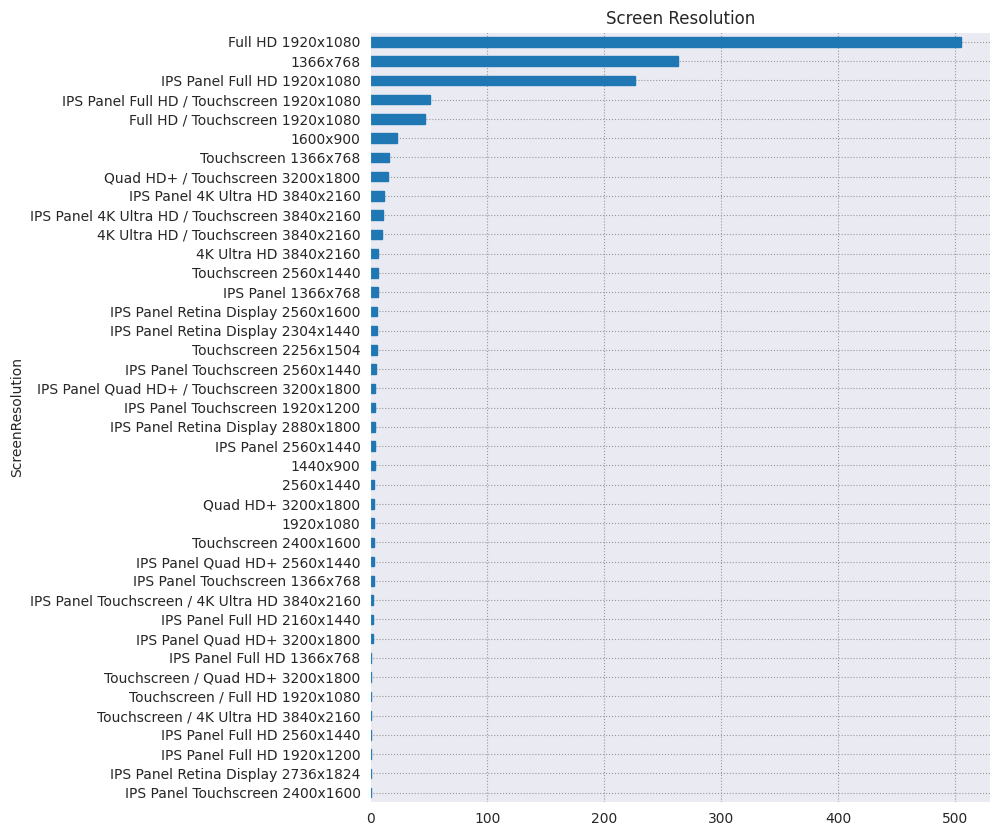

In [ ]:
resolution = df['ScreenResolution'].value_counts()
resolution = resolution.sort_values(ascending=True)
plt.figure(figsize=(8,10))
sns.set_style('darkgrid', {"grid.color": "0.6", "grid.linestyle": ":"})
resolution.plot(kind='barh', edgecolor='#1F77B4', title='Screen Resolution')
pd.DataFrame(resolution.sort_values(ascending=False))

,count
CPU_Company,
Intel,1214
AMD,60
Samsung,1


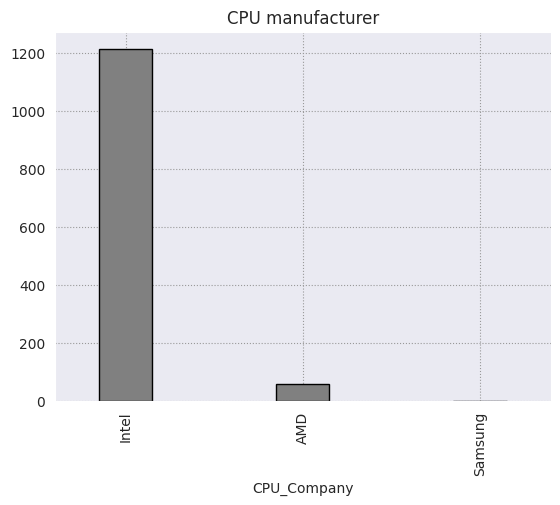

In [ ]:
CPU_company = df['CPU_Company'].value_counts()

CPU_company.plot(kind='bar', color='gray', edgecolor='black', width=0.3, title='CPU manufacturer')
pd.DataFrame(CPU_company)

,count
RAM (GB),
8,613
4,367
16,198
6,35
12,25
32,17
2,16
24,3
64,1


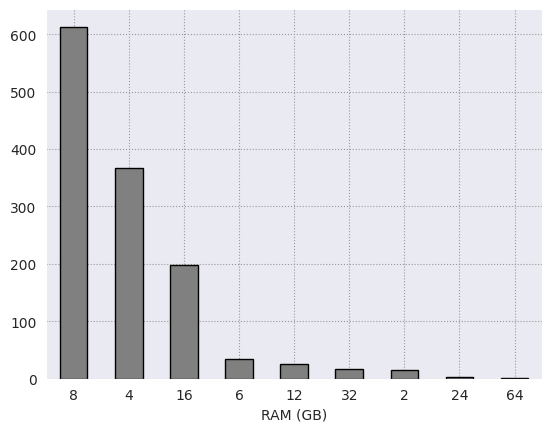

In [ ]:
RAM = df['RAM (GB)'].value_counts()

sns.set_style('darkgrid', {"grid.color": "0.6", "grid.linestyle": ":"})
RAM.plot(kind='bar', color='gray', edgecolor='black')
plt.xticks(rotation=0)
pd.DataFrame(RAM)

,count
CPU_Frequency (GHz),
2.50,285
2.80,165
2.70,164
1.60,124
2.30,86
2.00,86
1.80,78
2.60,74
1.10,53


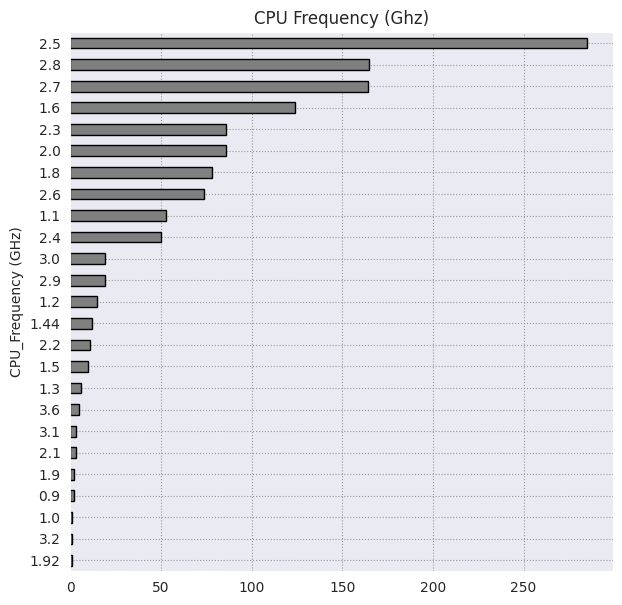

In [ ]:
freq = df['CPU_Frequency (GHz)'].value_counts()

plt.figure(figsize=(7,7))
sns.set_style('darkgrid', {"grid.color": "0.6", "grid.linestyle": ":"})
freq = freq.sort_values(ascending=True)
freq.plot(kind='barh', color='gray', edgecolor='black', title='CPU Frequency (Ghz)')
pd.DataFrame(freq.sort_values(ascending=False))

,count
Memory,
256GB SSD,412
1TB HDD,215
500GB HDD,124
512GB SSD,114
128GB SSD + 1TB HDD,94
128GB SSD,74
256GB SSD + 1TB HDD,73
32GB Flash Storage,36
2TB HDD,16


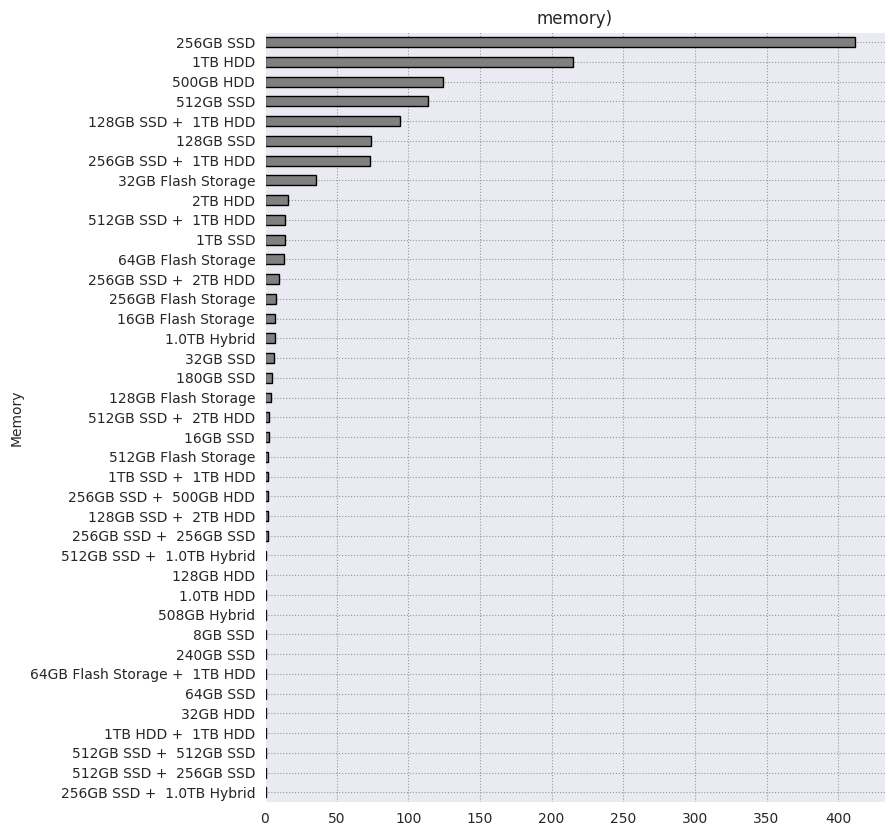

In [ ]:
memory = df['Memory'].value_counts()

plt.figure(figsize=(8,10))
sns.set_style('darkgrid', {"grid.color": "0.6", "grid.linestyle": ":"})
memory = memory.sort_values(ascending=True)
memory.plot(kind='barh', color='gray', edgecolor='black', title='memory)')
pd.DataFrame(memory.sort_values(ascending=False))

In [ ]:
df.columns

Index(['Company', 'Product', 'TypeName', 'Inches', 'ScreenResolution',
       'CPU_Company', 'CPU_Type', 'CPU_Frequency (GHz)', 'RAM (GB)', 'Memory',
       'GPU_Company', 'GPU_Type', 'OpSys', 'Weight (kg)', 'Price (Euro)'],
      dtype='object')

,count
GPU_Company,
Intel,704
Nvidia,396
AMD,174
ARM,1


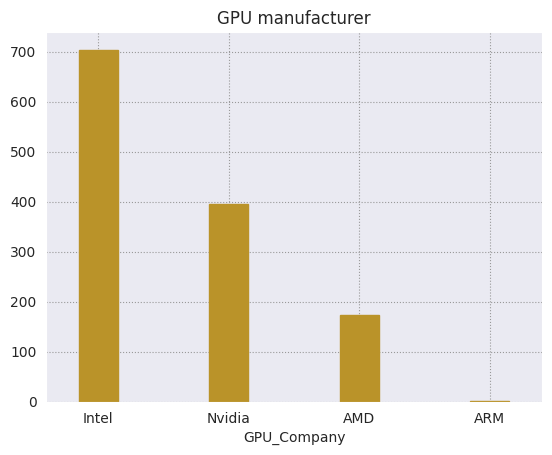

In [ ]:
GPU_Company = df['GPU_Company'].value_counts()
GPU_Company.plot(kind='bar', color='#BA9329', edgecolor='#BA9329', width=0.3, title='GPU manufacturer')
plt.xticks(rotation=0)
pd.DataFrame(GPU_Company)

,count
OpSys,
Windows 10,1048
No OS,66
Linux,58
Windows 7,45
Chrome OS,27
macOS,13
Mac OS X,8
Windows 10 S,8
Android,2


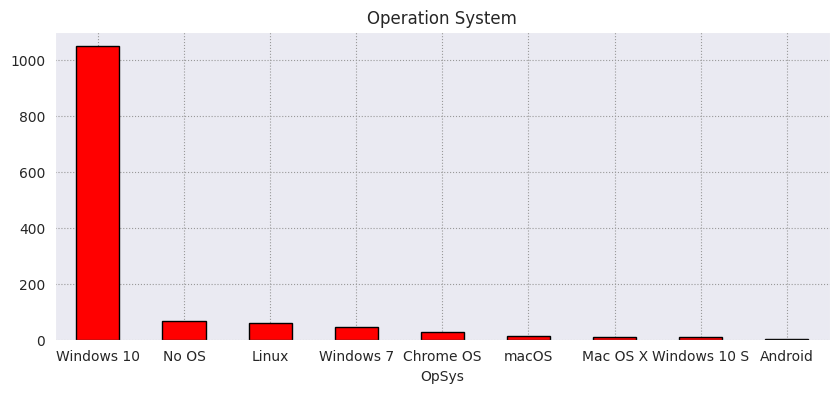

In [ ]:
OpSys = df['OpSys'].value_counts()
plt.figure(figsize=(10,4))
OpSys.plot(kind='bar', color='red', edgecolor='black',title ='Operation System')
plt.xticks(rotation=0)

pd.DataFrame(OpSys)

,Weight (kg)
count,1275.000000
mean,2.040525
std,0.669196
min,0.690000
25%,1.500000
50%,2.040000
75%,2.310000
max,4.700000


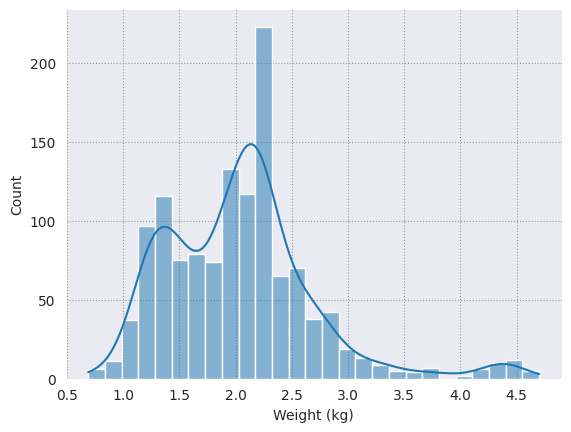

In [ ]:
weight = df['Weight (kg)']

sns.histplot(weight, kde=True)
plt.xticks(rotation=0)
pd.DataFrame(weight.describe())

,Price (Euro)
count,1275.000000
mean,1134.969059
std,700.752504
min,174.000000
25%,609.000000
50%,989.000000
75%,1496.500000
max,6099.000000


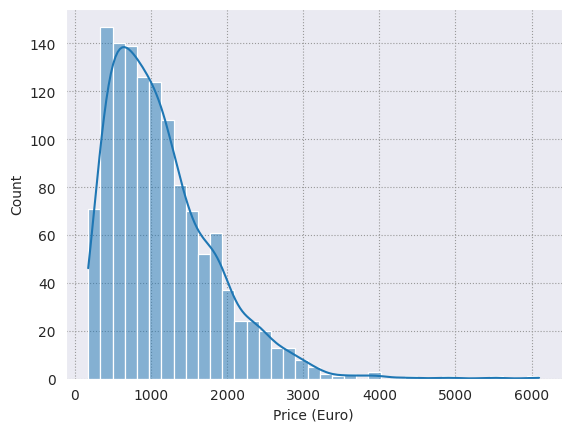

In [ ]:
price = df['Price (Euro)']

#plt.figure(figsize=(10,4))
sns.histplot(price, kde=True)
plt.xticks(rotation=0)
pd.DataFrame(price.describe())

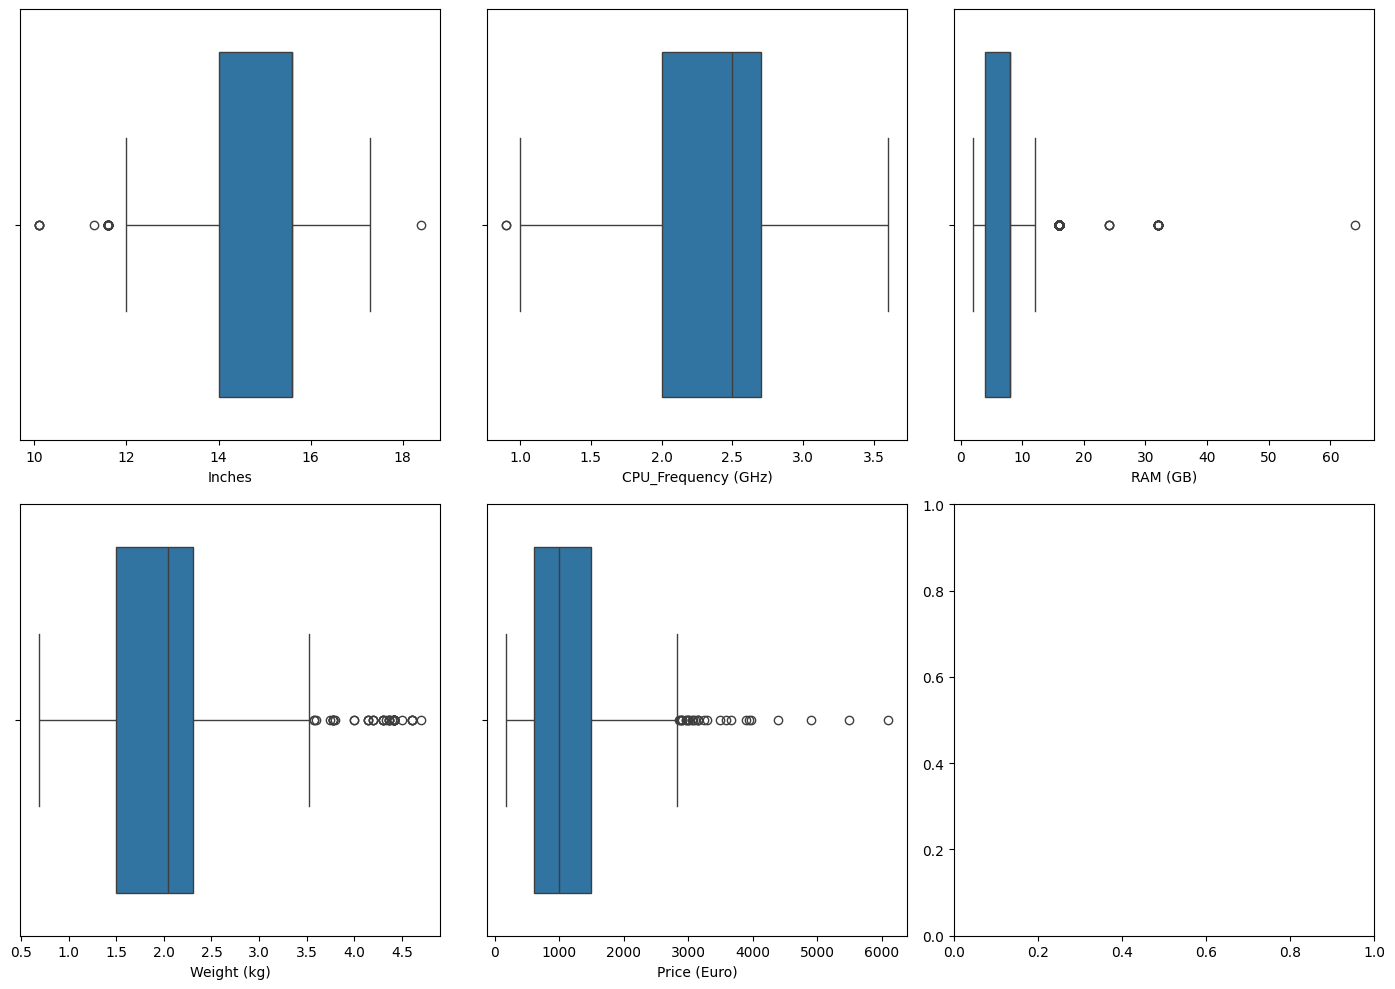

In [ ]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(14, 10))
for i, col in enumerate(numerical_col):
  row = i // 3
  column = i % 3
  ax = axes[row, column]
  sns.boxplot(x=df[col], ax=ax)
plt.tight_layout()
plt.show()

In [ ]:
numerical_col

['Inches', 'CPU_Frequency (GHz)', 'RAM (GB)', 'Weight (kg)', 'Price (Euro)']

In [ ]:
df['Weight (kg)'].value_counts()

,count
Weight (kg),
2.20,120
2.10,58
2.00,45
2.40,42
2.50,38
...,...
4.50,1
1.14,1
3.80,1


<ipython-input-68-4be426b56ce1>:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Inches', y='Price (Euro)', data=df, palette="viridis")


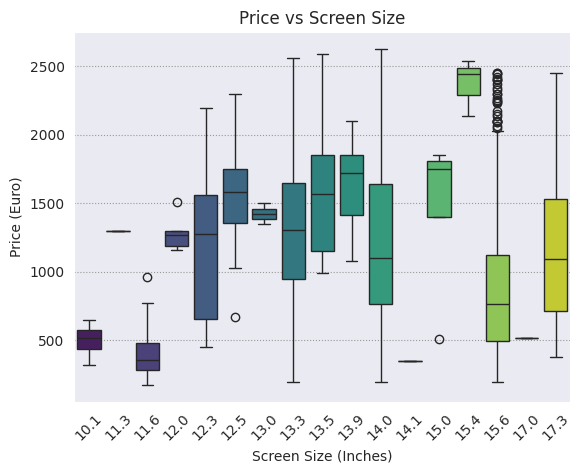

In [ ]:
sns.boxplot(x='Inches', y='Price (Euro)', data=df, palette="viridis")
plt.title("Price vs Screen Size")
plt.xlabel("Screen Size (Inches)")
plt.ylabel("Price (Euro)")
plt.xticks(rotation=45)
plt.show()

In [ ]:
def remove_outliers_IQR(data, column):
    # Обчислення Q1, Q3 та IQR
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1

    # Визначення меж для викидів
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Фільтрація даних
    filtered_data = data[(data[column] >= lower_bound) & (data[column] <= upper_bound)]

    return filtered_data

In [ ]:
ouliers_col = ['Weight (kg)']

In [ ]:
for col in ouliers_col:
  df = remove_outliers_IQR(df, col)

In [ ]:
df.isna().sum()

,0
Company,0
Product,0
TypeName,0
Inches,0
ScreenResolution,0
CPU_Company,0
CPU_Type,0
CPU_Frequency (GHz),0
RAM (GB),0
Memory,0


In [ ]:
for col in ouliers_col:
  df[col].fillna(df[col].median(), inplace=True)

<ipython-input-27-8599e793f552>:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].median(), inplace=True)
<ipython-input-27-8599e793f552>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[col].fillna(df[col].median(), inplace=True)


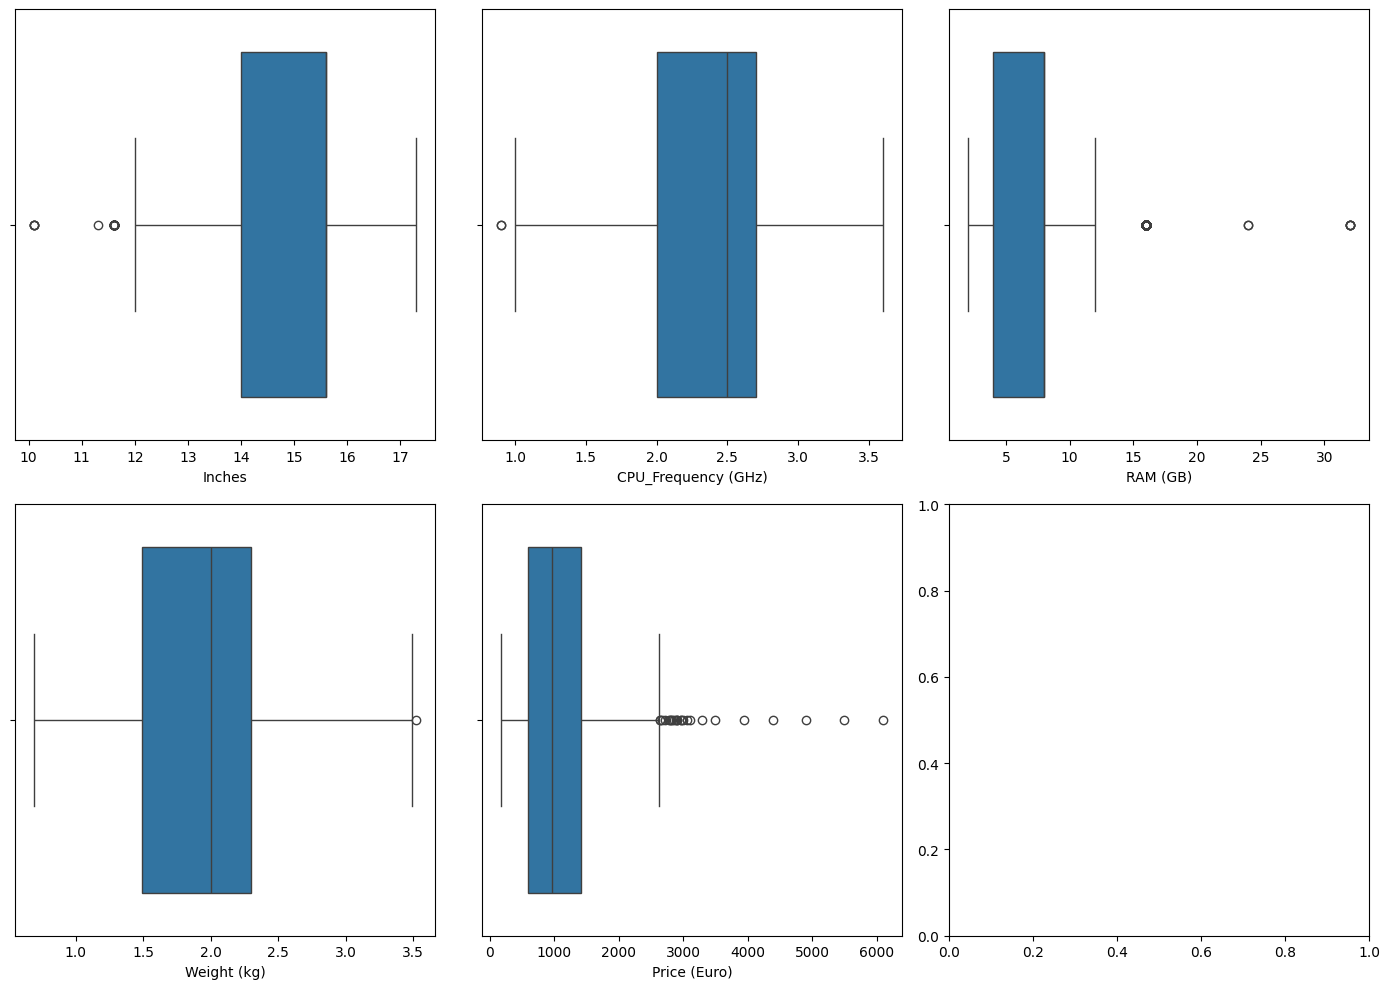

In [ ]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(14, 10))
for i, col in enumerate(numerical_col):
  row = i // 3
  column = i % 3
  ax = axes[row, column]
  sns.boxplot(x=df[col], ax=ax)
plt.tight_layout()
plt.show()


In [ ]:
df.shape

(1230, 15)

In [ ]:
from sklearn.preprocessing import MinMaxScaler

In [ ]:
scaler = MinMaxScaler()

In [ ]:
numerical_col

['Inches', 'CPU_Frequency (GHz)', 'RAM (GB)', 'Weight (kg)', 'Price (Euro)']

In [ ]:
data = scaler.fit_transform(df[numerical_col[:-1]])

In [ ]:
data

array([[0.44444444, 0.51851852, 0.2       , 0.24028269],
       [0.44444444, 0.33333333, 0.2       , 0.22968198],
       [0.76388889, 0.59259259, 0.2       , 0.41342756],
       ...,
       [0.54166667, 0.25925926, 0.        , 0.28621908],
       [0.76388889, 0.59259259, 0.13333333, 0.53003534],
       [0.76388889, 0.25925926, 0.06666667, 0.5335689 ]])

In [ ]:
data = pd.DataFrame(data, columns=[numerical_col[:-1]])
data

,Inches,CPU_Frequency (GHz),RAM (GB),Weight (kg)
0,0.444444,0.518519,0.200000,0.240283
1,0.444444,0.333333,0.200000,0.229682
2,0.763889,0.592593,0.200000,0.413428
3,0.736111,0.666667,0.466667,0.402827
4,0.444444,0.814815,0.200000,0.240283
...,...,...,...,...
1225,0.541667,0.592593,0.066667,0.392226
1226,0.444444,0.592593,0.466667,0.215548
1227,0.541667,0.259259,0.000000,0.286219
1228,0.763889,0.592593,0.133333,0.530035


In [ ]:
df[numerical_col[:-1]].head()

,Inches,CPU_Frequency (GHz),RAM (GB),Weight (kg)
0,13.3,2.3,8,1.37
1,13.3,1.8,8,1.34
2,15.6,2.5,8,1.86
3,15.4,2.7,16,1.83
4,13.3,3.1,8,1.37


In [ ]:
data.isna().sum()

,0
Inches,0
CPU_Frequency (GHz),0
RAM (GB),0
Weight (kg),0


In [ ]:
df.drop(columns=numerical_col[:-1], axis=1, inplace=True)

<ipython-input-38-bae0f3bb35ed>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.drop(columns=numerical_col[:-1], axis=1, inplace=True)


In [ ]:
df.head()

,Company,Product,TypeName,ScreenResolution,CPU_Company,CPU_Type,Memory,GPU_Company,GPU_Type,OpSys,Price (Euro)
0,Apple,MacBook Pro,Ultrabook,IPS Panel Retina Display 2560x1600,Intel,Core i5,128GB SSD,Intel,"(Iris, Plus, Graphics)",macOS,1339.69
1,Apple,Macbook Air,Ultrabook,1440x900,Intel,Core i5,128GB Flash Storage,Intel,"(HD, Graphics)",macOS,898.94
2,HP,250 G6,Notebook,Full HD 1920x1080,Intel,Core i5 7200U,256GB SSD,Intel,"(HD, Graphics)",No OS,575.00
3,Apple,MacBook Pro,Ultrabook,IPS Panel Retina Display 2880x1800,Intel,Core i7,512GB SSD,AMD,"(Radeon, Pro)",macOS,2537.45
4,Apple,MacBook Pro,Ultrabook,IPS Panel Retina Display 2560x1600,Intel,Core i5,256GB SSD,Intel,"(Iris, Plus, Graphics)",macOS,1803.60


In [ ]:
print("df index:\n", df.index)
print("data index:\n", data.index)

df index:
 Index([   0,    1,    2,    3,    4,    5,    6,    7,    8,    9,
       ...
       1265, 1266, 1267, 1268, 1269, 1270, 1271, 1272, 1273, 1274],
      dtype='int64', length=1230)
data index:
 RangeIndex(start=0, stop=1230, step=1)


In [ ]:
df.head()

,Company,Product,TypeName,ScreenResolution,CPU_Company,CPU_Type,Memory,GPU_Company,GPU_Type,OpSys,Price (Euro)
0,Apple,MacBook Pro,Ultrabook,IPS Panel Retina Display 2560x1600,Intel,Core i5,128GB SSD,Intel,"(Iris, Plus, Graphics)",macOS,1339.69
1,Apple,Macbook Air,Ultrabook,1440x900,Intel,Core i5,128GB Flash Storage,Intel,"(HD, Graphics)",macOS,898.94
2,HP,250 G6,Notebook,Full HD 1920x1080,Intel,Core i5 7200U,256GB SSD,Intel,"(HD, Graphics)",No OS,575.00
3,Apple,MacBook Pro,Ultrabook,IPS Panel Retina Display 2880x1800,Intel,Core i7,512GB SSD,AMD,"(Radeon, Pro)",macOS,2537.45
4,Apple,MacBook Pro,Ultrabook,IPS Panel Retina Display 2560x1600,Intel,Core i5,256GB SSD,Intel,"(Iris, Plus, Graphics)",macOS,1803.60


In [ ]:
df.isna().sum()

,0
Company,0
Product,0
TypeName,0
ScreenResolution,0
CPU_Company,0
CPU_Type,0
Memory,0
GPU_Company,0
GPU_Type,0
OpSys,0


In [ ]:
category_col

['Company',
 'Product',
 'TypeName',
 'ScreenResolution',
 'CPU_Company',
 'CPU_Type',
 'Memory',
 'GPU_Company',
 'GPU_Type',
 'OpSys']

In [ ]:
from scipy.stats import f_oneway

In [ ]:
for col in category_col:
  CategoryGroupLists = df.groupby(col)['Price (Euro)'].apply(list)
  AnovaResults = f_oneway(*CategoryGroupLists)
  print(col, ': ', 'P-Value for anova is : ', AnovaResults[1])

Company :  P-Value for anova is :  1.2223664734741346e-43
Product :  P-Value for anova is :  5.28649539765695e-141
TypeName :  P-Value for anova is :  8.425426827534984e-116
ScreenResolution :  P-Value for anova is :  4.060051926423692e-116
CPU_Company :  P-Value for anova is :  6.650623768381699e-10
CPU_Type :  P-Value for anova is :  7.266702004639753e-194
Memory :  P-Value for anova is :  9.22363820869794e-177
GPU_Company :  P-Value for anova is :  8.44329961738679e-26
GPU_Type :  P-Value for anova is :  1.2871782008577885e-71
OpSys :  P-Value for anova is :  2.2347555983395624e-29


since category_cols p-value is really small we will use all of them

In [ ]:
df.head()

,Company,Product,TypeName,ScreenResolution,CPU_Company,CPU_Type,Memory,GPU_Company,GPU_Type,OpSys,Price (Euro)
0,Apple,MacBook Pro,Ultrabook,IPS Panel Retina Display 2560x1600,Intel,Core i5,128GB SSD,Intel,"(Iris, Plus, Graphics)",macOS,1339.69
1,Apple,Macbook Air,Ultrabook,1440x900,Intel,Core i5,128GB Flash Storage,Intel,"(HD, Graphics)",macOS,898.94
2,HP,250 G6,Notebook,Full HD 1920x1080,Intel,Core i5 7200U,256GB SSD,Intel,"(HD, Graphics)",No OS,575.00
3,Apple,MacBook Pro,Ultrabook,IPS Panel Retina Display 2880x1800,Intel,Core i7,512GB SSD,AMD,"(Radeon, Pro)",macOS,2537.45
4,Apple,MacBook Pro,Ultrabook,IPS Panel Retina Display 2560x1600,Intel,Core i5,256GB SSD,Intel,"(Iris, Plus, Graphics)",macOS,1803.60


In [ ]:
df_encoded = pd.get_dummies(df[category_col], columns=category_col, drop_first=True).astype(int)

df_encoded

,Company_Apple,Company_Asus,Company_Chuwi,Company_Dell,Company_Fujitsu,Company_Google,Company_HP,Company_Huawei,Company_LG,Company_Lenovo,...,"GPU_Type_('Radeon', 'RX')","GPU_Type_('UHD', 'Graphics')",OpSys_Chrome OS,OpSys_Linux,OpSys_Mac OS X,OpSys_No OS,OpSys_Windows 10,OpSys_Windows 10 S,OpSys_Windows 7,OpSys_macOS
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
1,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
2,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,1,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
4,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1270,0,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,1,0,0,0
1271,0,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,1,0,0,0
1272,0,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,1,0,0,0
1273,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,1,0,0,0


In [ ]:
df_encoded.shape

(1230, 814)

In [ ]:
df_reset = data.reset_index(drop=True)
df_encoded_reset = df_encoded.reset_index(drop=True)

new_df = pd.concat([df_reset, df_encoded_reset, df['Price (Euro)'].reset_index(drop=True)], axis=1)
new_df.head()


,"(Inches,)","(CPU_Frequency (GHz),)","(RAM (GB),)","(Weight (kg),)",Company_Apple,Company_Asus,Company_Chuwi,Company_Dell,Company_Fujitsu,Company_Google,...,"GPU_Type_('UHD', 'Graphics')",OpSys_Chrome OS,OpSys_Linux,OpSys_Mac OS X,OpSys_No OS,OpSys_Windows 10,OpSys_Windows 10 S,OpSys_Windows 7,OpSys_macOS,Price (Euro)
0,0.444444,0.518519,0.200000,0.240283,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,1339.69
1,0.444444,0.333333,0.200000,0.229682,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,898.94
2,0.763889,0.592593,0.200000,0.413428,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,575.00
3,0.736111,0.666667,0.466667,0.402827,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,2537.45
4,0.444444,0.814815,0.200000,0.240283,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,1803.60


In [ ]:
new_df.isna().sum()

,0
"(Inches,)",0
"(CPU_Frequency (GHz),)",0
"(RAM (GB),)",0
"(Weight (kg),)",0
Company_Apple,0
...,...
OpSys_Windows 10,0
OpSys_Windows 10 S,0
OpSys_Windows 7,0
OpSys_macOS,0


In [ ]:
new_df.to_csv('./clean_laptop_price.csv', index=False)

In [ ]:
import pandas as pd

In [ ]:
clean_df = pd.read_csv('./clean_laptop_price.csv')
clean_df.head()

,"('Inches',)","('CPU_Frequency (GHz)',)","('RAM (GB)',)","('Weight (kg)',)",Company_Apple,Company_Asus,Company_Chuwi,Company_Dell,Company_Fujitsu,Company_Google,...,"GPU_Type_('UHD', 'Graphics')",OpSys_Chrome OS,OpSys_Linux,OpSys_Mac OS X,OpSys_No OS,OpSys_Windows 10,OpSys_Windows 10 S,OpSys_Windows 7,OpSys_macOS,Price (Euro)
0,0.444444,0.518519,0.200000,0.240283,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,1339.69
1,0.444444,0.333333,0.200000,0.229682,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,898.94
2,0.763889,0.592593,0.200000,0.413428,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,575.00
3,0.736111,0.666667,0.466667,0.402827,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,2537.45
4,0.444444,0.814815,0.200000,0.240283,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,1803.60


In [ ]:
clean_df.isna().sum()

,0
"('Inches',)",0
"('CPU_Frequency (GHz)',)",0
"('RAM (GB)',)",0
"('Weight (kg)',)",0
Company_Apple,0
...,...
OpSys_Windows 10,0
OpSys_Windows 10 S,0
OpSys_Windows 7,0
OpSys_macOS,0


In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split

In [ ]:
X = clean_df.drop('Price (Euro)', axis=1)
y = clean_df['Price (Euro)']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,random_state=42)

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

In [ ]:
print(f'Shape of X_test: {X_test.shape}')
print(f'Shape of y_test: {y_test.shape}')

Shape of X_test: (246, 818)
Shape of y_test: (246,)


R^2 score: -6994070007716893559881728.00


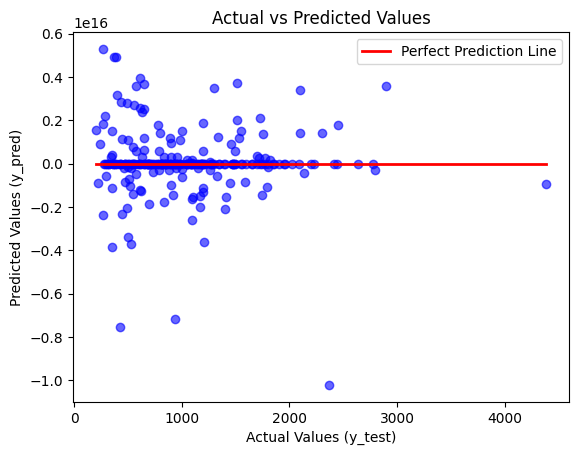

In [ ]:
import matplotlib as plt
# Create a linear regression model
lr_model = LinearRegression()

# Train the model on the training data
lr_model.fit(X_train, y_train)

# Make predictions on the test data
y_pred = lr_model.predict(X_test)

# Calculate and print the R^2 score
r2 = r2_score(y_test, y_pred)
print(f'R^2 score: {r2:.2f}')

import matplotlib.pyplot as plt

# Scatter plot: Actual vs Predicted values
plt.scatter(y_test, y_pred, color='blue', alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linewidth=2, label='Perfect Prediction Line')
plt.xlabel('Actual Values (y_test)')
plt.ylabel('Predicted Values (y_pred)')
plt.title('Actual vs Predicted Values')
plt.legend()
plt.show()

In [ ]:
from sklearn.tree import DecisionTreeRegressor
dt_model = DecisionTreeRegressor()
dt_model.fit(X_train, y_train)
y_pred = dt_model.predict(X_test)
res = r2_score(y_test, y_pred)
print(res)

0.5191799566777902


In [ ]:
print("Linear Regression Predictions:", lr_model.predict(X_test))
print("Decision Tree Predictions:", dt_model.predict(X_test))
print("True Values:", y_test)


Linear Regression Predictions: [-1.10341681e+15  1.32775000e+03  7.55875000e+02 -1.76271853e+15
  2.38201167e+15  2.57532497e+15  3.88875000e+02 -2.09217098e+15
 -3.85197742e+15  1.28825000e+03  1.37012500e+03  8.09625000e+02
 -1.55435878e+15  7.93500000e+02 -1.39581769e+15 -2.30696361e+15
  9.65750000e+02  3.65000000e+02  6.44500000e+02 -2.61834481e+14
  3.14843482e+15  2.82462500e+03  2.57938185e+14  8.64125000e+02
  1.78775000e+03  3.03600000e+03  8.17250000e+02 -1.46720736e+15
 -2.17140385e+14  5.87750000e+02  6.04250000e+02  1.59825000e+03
  7.37750000e+02 -2.17140385e+14  4.19250000e+02  1.20647545e+13
  2.30575000e+03  1.87788827e+15 -8.50241526e+14 -1.27298438e+15
 -1.52742886e+15  6.41050401e+14  5.48875000e+02  1.13625000e+03
  9.28500000e+02  9.27750000e+02  1.35625000e+03  1.71925000e+03
  1.11821600e+15 -2.17140385e+14  7.71000000e+02  4.32750000e+02
  3.37630967e+15  1.52745750e+15  1.09155427e+15  9.17079970e+14
 -7.18587158e+15  2.31112500e+03  6.20625000e+02 -3.6291412

In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_pred = rf_model.predict(X_test)
print("R^2 score (Random Forest):", r2_score(y_test, y_pred))


R^2 score (Random Forest): 0.7193606391196179


In [ ]:
 import xgboost as xgb
 model = xgb.XGBRegressor()
 model.fit(X_train, y_train)
 y_pred = model.predict(X_test)

 r2 = r2_score(y_test, y_pred)
 print(f'R^2 score: {r2:.2f}')

R^2 score: 0.84


In [ ]:
from sklearn.model_selection import GridSearchCV
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.1, 0.2]
}
#estimates the best parametrs (n_estimators, max_depth, learning_rate)
grid_search = GridSearchCV(estimator=model, param_grid=param_grid, cv=5, scoring='r2')
grid_search.fit(X_train, y_train)
best_params = grid_search.best_params_
print(best_params)
best_model = xgb.XGBRegressor(**best_params)
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)
r2 = r2_score(y_test, y_pred)
print(r2)


{'learning_rate': 0.2, 'max_depth': 4, 'n_estimators': 300}
0.8021535529319542
